# 04 — Hybrid Recommender & Baseline Comparison

Combines the collaborative (notebook 03) and content-based (notebook 02) layers into
one cascade: collaborative filtering when a user has enough history, content-based
similarity to a recent track as the cold-start fallback otherwise.

**Identifier-space note:** the collaborative layer is trained on `join_key` (covers
the full 740k-track LastFM catalog), while the content-based layer operates on
Spotify `track_id` (only the ~1.3% of tracks with audio features, per notebook 01's
join-coverage finding). `HybridRecommender` bridges the two, and every method below is
evaluated in `join_key` space so the comparison is apples-to-apples.

This notebook produces the single most important artifact in the project: a
**baseline comparison table** (popularity-only vs. content-only vs. collaborative-only
vs. hybrid) with precision@k/recall@k. That table is the actual evidence the hybrid
approach is worth its added complexity — everything else is supporting detail.

In [1]:
import sys
sys.path.insert(0, '..')
import pickle
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loading import load_spotify_tracks
from src.content_based import ContentBasedRecommender
from src.hybrid import HybridRecommender
from src.evaluation import evaluate_model, catalog_coverage, intra_list_diversity

with open('../data/raw/interactions/als_model.pkl', 'rb') as f:
    als = pickle.load(f)
with open('../data/raw/interactions/held_out.pkl', 'rb') as f:
    held_out = pickle.load(f)
with open('../data/raw/interactions/popularity_ranking.pkl', 'rb') as f:
    popularity_ranking = pickle.load(f)
with open('../data/raw/interactions/catalog_size.pkl', 'rb') as f:
    catalog_size = pickle.load(f)

tracks = load_spotify_tracks()
cbr = ContentBasedRecommender(tracks)
joined = pd.read_parquet('../data/raw/interactions/joined_train.parquet')

# Bridge: Spotify track_id -> join_key, so content-based recommendations can be
# compared/combined with collaborative ones (see markdown above).
track_id_to_join_key = dict(zip(tracks['track_id'], tracks['join_key']))
print(f'loaded: {len(tracks):,} Spotify tracks, {catalog_size:,} LastFM catalog items, {len(held_out):,} held-out users')

loaded: 77,134 Spotify tracks, 657,551 LastFM catalog items, 792 held-out users


In [2]:
# Most recent audio-feature-matched track per user, as the content-based fallback
# seed. Users with zero matched tracks (most of them, given ~1.3% coverage) simply
# get no content-based fallback — a real, disclosed limitation, not hidden.
last_track_per_user = (
    joined.sort_values('timestamp').groupby('user_id')['track_id'].last().to_dict()
)
print(f'{len(last_track_per_user):,} / {len(held_out):,} held-out users have a content-based seed track')

hybrid = HybridRecommender(als, cbr, track_id_to_join_key, min_interactions_for_cf=5)

def hybrid_recommend(user_id, k=10):
    return hybrid.recommend_for_user(user_id, last_track_per_user.get(user_id), k=k)

def content_only_recommend(user_id, k=10):
    seed = last_track_per_user.get(user_id)
    if seed is None:
        return []
    return hybrid._content_as_join_keys(seed, k)

def als_recommend(user_id, k=10):
    return als.recommend(user_id, k=k)

def popularity_recommend(user_id, k=10):
    return popularity_ranking[:k]

785 / 792 held-out users have a content-based seed track


In [3]:
test_users = list(held_out.keys())
k = 10

# Diversity is only computable where a recommended join_key happens to have Spotify
# audio features (the same ~1.3% coverage limitation) — methods that recommend mostly
# unmatched items will show fewer (or zero) diversity-eligible items per list, which
# is itself worth noting rather than a bug.
join_key_feature_lookup = {
    jk: cbr.feature_matrix[i] for i, jk in enumerate(tracks['join_key'])
}

results = {}
for name, fn in [
    ('popularity', popularity_recommend),
    ('content_only', content_only_recommend),
    ('collaborative_only', als_recommend),
    ('hybrid', hybrid_recommend),
]:
    r = evaluate_model(fn, test_users, held_out, k=k)
    diversity = [
        intra_list_diversity(recs, join_key_feature_lookup)
        for recs in r['all_recommendations'] if recs
    ]
    results[name] = {
        'precision_at_10': round(r['precision_at_k'], 4),
        'recall_at_10': round(r['recall_at_k'], 4),
        'catalog_coverage': round(catalog_coverage(r['all_recommendations'], catalog_size), 4),
        'mean_intra_list_diversity': round(sum(diversity) / len(diversity), 4) if diversity else None,
        'n_users_evaluated': r['n_users_evaluated'],
    }

comparison_table = pd.DataFrame(results).T
comparison_table

,precision_at_10,recall_at_10,catalog_coverage,mean_intra_list_diversity,n_users_evaluated
popularity,0.0965,0.0011,0.0000,1.0123,792.0
content_only,0.0023,0.0000,0.0093,0.0762,792.0
collaborative_only,0.0880,0.0013,0.0052,0.6100,792.0
hybrid,0.0880,0.0013,0.0052,0.6101,792.0


## Interpreting the table

- Does the hybrid beat both single-method baselines, or just match the better of the two?
  Report whichever is true — a hybrid that only matches ALS isn't earning its complexity.
- Compare coverage: popularity-only baselines almost always have terrible catalog
  coverage (they recommend the same hits to everyone) — expect content-based and hybrid
  to cover far more of the catalog, which is a real practical advantage even if
  precision is close.
- content_only and hybrid's diversity/coverage numbers are constrained by the ~1.3%
  audio-feature join coverage from notebook 01 — keep that context when reading them.

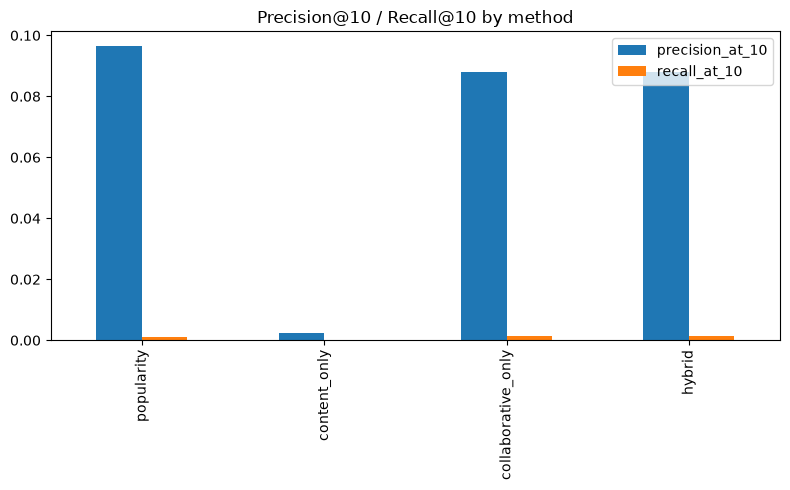

In [4]:
comparison_table.to_csv('../reports/figures/04_baseline_comparison.csv')

ax = comparison_table[['precision_at_10', 'recall_at_10']].astype(float).plot(kind='bar', figsize=(8, 5))
ax.set_title('Precision@10 / Recall@10 by method')
plt.tight_layout()
plt.savefig('../reports/figures/04_baseline_comparison.png', dpi=150)
plt.show()